In [1]:
import os
import cv2
import torch
import pandas as pd
import torch.nn as nn
import random
import itertools
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
from torch.optim import AdamW

from sklearn.metrics import accuracy_score

In [2]:
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:3


In [4]:
class ImageDataset(Dataset):
    def __init__(self, folder, csv_path, size=(224, 224), mean=None, std=None):
        df = pd.read_csv(csv_path, usecols=["filename", "category_id"])
        self.files = df["filename"].astype(str).tolist()
        self.labels = df["category_id"].astype(int).tolist()
        self.folder = folder
        self.size = size
        self.normalize = mean is not None and std is not None

        if self.normalize:
            self.mean = torch.as_tensor(mean, dtype=torch.float32).view(3, 1, 1)
            self.std = torch.as_tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = os.path.join(self.folder, self.files[idx])
        img = cv2.imread(path)
        if img is None:
            raise ValueError(f"Could not read image: {path}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, self.size, interpolation=cv2.INTER_AREA)

        img = torch.from_numpy(img).permute(2, 0, 1).float().div_(255.0)

        if self.normalize:
            img = (img - self.mean) / self.std

        return img, self.labels[idx]

In [5]:
@torch.no_grad()
def compute_mean_std(dataset, batch_size=64, num_workers=4):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    n_pixels = 0
    ch_sum = torch.zeros(3, dtype=torch.float64)
    ch_sqsum = torch.zeros(3, dtype=torch.float64)

    for x, _ in loader:
        x = x.double()
        n_pixels += x.shape[0] * x.shape[2] * x.shape[3]
        ch_sum += x.sum(dim=(0, 2, 3))
        ch_sqsum += (x ** 2).sum(dim=(0, 2, 3))

    mean = ch_sum / n_pixels
    std = (ch_sqsum / n_pixels - mean ** 2).sqrt()
    return mean.float().tolist(), std.float().tolist()

In [6]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

In [7]:
train_ds = ImageDataset("dataset_updated/224x224", "dataset_updated/train/listings_train.csv", mean=mean, std=std)
val_ds = ImageDataset("dataset_updated/224x224", "dataset_updated/validation/listings_val.csv", mean=mean, std=std)
test_ds = ImageDataset("dataset_updated/224x224", "dataset_updated/test/listings_test.csv", mean=mean, std=std)

In [8]:
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

train 45593 | val 5700 | test 5700


In [9]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=4, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=4)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=4)

Basis:
https://www.mdpi.com/2226-4310/13/10/864#Network_Model_a4

In [10]:
class CoordAtt(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()

        mid = max(8, channels // reduction)

        self.conv1 = nn.Conv2d(channels, mid, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid)
        self.act = nn.Hardswish()

        self.conv_h = nn.Conv2d(mid, channels, kernel_size=1)
        self.conv_w = nn.Conv2d(mid, channels, kernel_size=1)

    def forward(self, x):
        _, _, h, w = x.shape

        x_h = x.mean(dim=3, keepdim=True)

        x_w = x.mean(dim=2, keepdim=True).permute(0, 1, 3, 2)

        y = torch.cat([x_h, x_w], dim=2)

        y = self.act(self.bn1(self.conv1(y)))
        y_h, y_w = torch.split(y, [h, w], dim=2)

        y_w = y_w.permute(0, 1, 3, 2)

        a_h = torch.sigmoid(self.conv_h(y_h))
        a_w = torch.sigmoid(self.conv_w(y_w))

        return x * a_h * a_w

In [11]:
class Bottleneck(nn.Module):
    expansion = 4
    
    def __init__(self, in_channels, channels, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, channels, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
        self.conv3 = nn.Conv2d(channels, channels * self.expansion, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(channels * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return self.relu(out + identity)

In [12]:
class ResNetCA(nn.Module):
    def __init__(self, in_channels=3, num_classes=30, layers=(3, 4, 6, 3), dropout=0.3):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv2d(in_channels, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, 2, 1)

        self.layer1 = self._make_layer(64,  layers[0], stride=1)   # -> 256
        self.layer2 = self._make_layer(128, layers[1], stride=2)   # -> 512
        self.layer3 = self._make_layer(256, layers[2], stride=2)   # -> 1024
        self.layer4 = self._make_layer(512, layers[3], stride=2)   # -> 2048

        self.att1 = CoordAtt(512)    # after layer2 (128 * 4)
        self.att2 = CoordAtt(2048)   # after layer4 (512 * 4)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(2048, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )
        self._initialize_weights()

In [13]:
def make_layer(self, channels, blocks, stride):
    out_channels = channels * Bottleneck.expansion
    downsample = None
    if stride != 1 or self.in_channels != out_channels:
        downsample = nn.Sequential(
            nn.Conv2d(self.in_channels, out_channels, 1, stride, bias=False),
            nn.BatchNorm2d(out_channels),
        )
    layers = [Bottleneck(self.in_channels, channels, stride, downsample)]
    self.in_channels = out_channels
    layers += [Bottleneck(self.in_channels, channels) for _ in range(1, blocks)]
    return nn.Sequential(*layers)

ResNetCA._make_layer = make_layer

In [14]:
def forward(self, x):
    x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
    x = self.layer1(x)
    x = self.att1(self.layer2(x))
    x = self.layer3(x)
    x = self.att2(self.layer4(x))
    x = torch.flatten(self.gap(x), 1)
    return self.fc(x)

ResNetCA.forward = forward

In [15]:
def initialize_weights(self):
    for m in self.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.constant_(m.weight, 1); nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0, 0.01); nn.init.constant_(m.bias, 0)

ResNetCA._initialize_weights = initialize_weights

In [ ]:
def build_model():
    
    model = ResNetCA(in_channels=3, num_classes=30).to(device)
    pre = torchvision.models.resnet50(weights="IMAGENET1K_V1").state_dict()
    pre = {k: v for k, v in pre.items() if not k.startswith("fc.")}
    
    missing, unexpected = model.load_state_dict(pre, strict=False)
    
    for m in model.modules():
        if isinstance(m, Bottleneck):
            nn.init.constant_(m.bn3.weight, 0)
            
    return model

In [16]:
import torchvision

model = ResNetCA(in_channels=3, num_classes=30).to(device)

pre = torchvision.models.resnet50(weights="IMAGENET1K_V1").state_dict()
pre = {k: v for k, v in pre.items() if not k.startswith("fc.")}

missing, unexpected = model.load_state_dict(pre, strict=False)
print("Missing:", missing)

Missing: ['att1.conv1.weight', 'att1.bn1.weight', 'att1.bn1.bias', 'att1.bn1.running_mean', 'att1.bn1.running_var', 'att1.conv_h.weight', 'att1.conv_h.bias', 'att1.conv_w.weight', 'att1.conv_w.bias', 'att2.conv1.weight', 'att2.bn1.weight', 'att2.bn1.bias', 'att2.bn1.running_mean', 'att2.bn1.running_var', 'att2.conv_h.weight', 'att2.conv_h.bias', 'att2.conv_w.weight', 'att2.conv_w.bias', 'fc.1.weight', 'fc.1.bias', 'fc.4.weight', 'fc.4.bias']


In [17]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 24,463,358
Trainable parameters: 24,463,358


In [18]:
from torch.optim import SGD, AdamW
from sklearn.metrics import accuracy_score

In [19]:
for m in [model.conv1, model.bn1, model.layer1, model.layer2]:
    for p in m.parameters():
        p.requires_grad = False

backbone = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith(("layer3", "layer4"))]
head     = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith(("layer3", "layer4"))]

optimizer = torch.optim.AdamW([{"params": backbone, "lr": 1e-5}, {"params": head, "lr": 1e-3},], weight_decay=0.05)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

In [20]:
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

epochs, warmup = 30, 2
s1 = LinearLR(optimizer, start_factor=0.1, total_iters=warmup)
s2 = CosineAnnealingLR(optimizer, T_max=epochs - warmup)
scheduler = SequentialLR(optimizer, [s1, s2], milestones=[warmup])

In [21]:
def train_one_epoch(model, loader, criterion, optimizer, device, scaler=None):
    model.train()
    for m in [model.bn1, model.layer1, model.layer2]:
        m.eval()
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)          
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=scaler is not None):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

In [22]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, top3, top5, total = 0.0, 0, 0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            topk = outputs.topk(5, dim=1).indices            # (N, 5)
            hits = topk == labels.unsqueeze(1)                # (N, 5) bool

            total_loss += loss.item() * labels.size(0)
            correct += hits[:, :1].any(1).sum().item()        # top-1
            top3    += hits[:, :3].any(1).sum().item()
            top5    += hits.any(1).sum().item()
            total   += labels.size(0)

    return total_loss / total, correct / total, top3 / total, top5 / total

In [23]:
num_epochs = 30
best_val_acc = 0
best_val_loss = float("inf")
patience = 6
bad_epochs = 0
train_losses, val_losses, train_accs, val_accs = [], [], [], []

In [25]:
for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, val_top3, val_top5 = evaluate(model, val_loader, criterion, device)

    train_losses.append(train_loss); val_losses.append(val_loss)
    train_accs.append(train_acc); val_accs.append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_resnet34_coordatt_acc.pth")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        bad_epochs = 0
        torch.save(model.state_dict(), "best_resnet50_coordatt_loss.pth")
    else:
        bad_epochs += 1

    print(f"Epoch [{epoch+1}/{num_epochs}] LR: {current_lr:.5f}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Top-3: {val_top3:.4f} | Top-5: {val_top5:.4f}")

    if bad_epochs >= patience:
        print(f"Early stopping at epoch {epoch+1}. "
              f"Best val loss: {best_val_loss:.4f} | Best val acc: {best_val_acc:.4f}")
        break

Epoch [1/30] LR: 0.00000
Train Loss: 2.9388 | Train Acc: 0.2079
Val Loss: 2.8787 | Val Acc: 0.2316 | Top-3: 0.4235 | Top-5: 0.5407
Epoch [2/30] LR: 0.00001
Train Loss: 2.8210 | Train Acc: 0.2455
Val Loss: 2.7552 | Val Acc: 0.2696 | Top-3: 0.4684 | Top-5: 0.5835
Epoch [3/30] LR: 0.00001
Train Loss: 2.6740 | Train Acc: 0.2890
Val Loss: 2.6912 | Val Acc: 0.2975 | Top-3: 0.4925 | Top-5: 0.6193
Epoch [4/30] LR: 0.00001
Train Loss: 2.4527 | Train Acc: 0.3627
Val Loss: 2.7399 | Val Acc: 0.2889 | Top-3: 0.4861 | Top-5: 0.6063
Epoch [5/30] LR: 0.00001
Train Loss: 2.1793 | Train Acc: 0.4542
Val Loss: 2.7931 | Val Acc: 0.2939 | Top-3: 0.4956 | Top-5: 0.6102
Epoch [6/30] LR: 0.00001
Train Loss: 1.8829 | Train Acc: 0.5600
Val Loss: 2.9516 | Val Acc: 0.2712 | Top-3: 0.4696 | Top-5: 0.5879
Epoch [7/30] LR: 0.00001
Train Loss: 1.5983 | Train Acc: 0.6707
Val Loss: 3.0822 | Val Acc: 0.2647 | Top-3: 0.4656 | Top-5: 0.5816
Epoch [8/30] LR: 0.00001
Train Loss: 1.3525 | Train Acc: 0.7705
Val Loss: 3.2327 | 

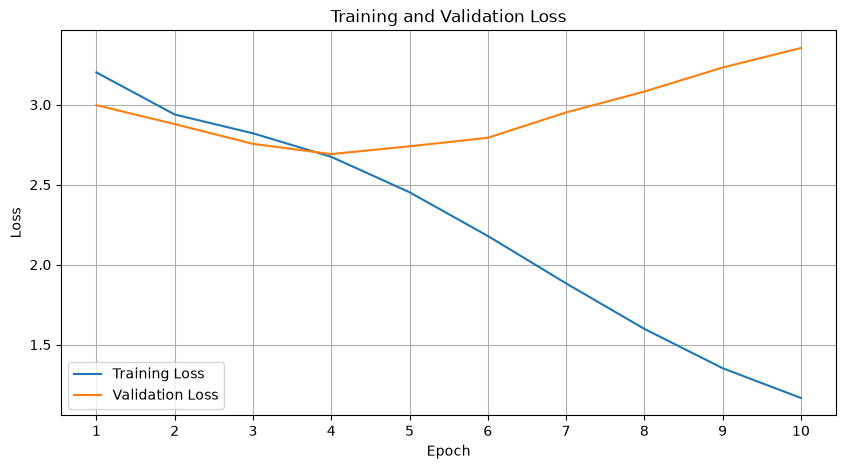

In [26]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.xticks(epochs)
plt.show()

In [27]:
model.load_state_dict(torch.load("best_resnet50_coordatt.pth"))

RuntimeError: Error(s) in loading state_dict for ResNetCA:
	Missing key(s) in state_dict: "fc.1.weight", "fc.1.bias", "fc.4.weight", "fc.4.bias". 
	Unexpected key(s) in state_dict: "att3.conv1.weight", "att3.bn1.weight", "att3.bn1.bias", "att3.bn1.running_mean", "att3.bn1.running_var", "att3.bn1.num_batches_tracked", "att3.conv_h.weight", "att3.conv_h.bias", "att3.conv_w.weight", "att3.conv_w.bias", "att4.conv1.weight", "att4.bn1.weight", "att4.bn1.bias", "att4.bn1.running_mean", "att4.bn1.running_var", "att4.bn1.num_batches_tracked", "att4.conv_h.weight", "att4.conv_h.bias", "att4.conv_w.weight", "att4.conv_w.bias", "fc.weight", "fc.bias". 
	size mismatch for att1.conv1.weight: copying a param with shape torch.Size([8, 256, 1, 1]) from checkpoint, the shape in current model is torch.Size([16, 512, 1, 1]).
	size mismatch for att1.bn1.weight: copying a param with shape torch.Size([8]) from checkpoint, the shape in current model is torch.Size([16]).
	size mismatch for att1.bn1.bias: copy

In [27]:
param_grid = {
    "lr": [0.01, 0.03, 0.1],
    "weight_decay": [1e-4, 5e-4]
}

In [ ]:
def run_trial(lr, wd, epochs=12):
    torch.manual_seed(42)

    model = ResNet50(num_classes=30).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=2)
    best_acc, best_state, patience = 0, None, 0

    for epoch in range(epochs):
        train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        scheduler.step(val_loss)
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1
        if patience >= 3:
            break

    return best_acc, best_state

In [ ]:
from itertools import product

results = []
best_acc = 0
best_config = None

for lr, wd in product(param_grid["lr"], param_grid["weight_decay"]):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    val_acc, state = run_trial(lr, wd)

    results.append({
        "lr": lr,
        "weight_decay": wd,
        "val_acc": val_acc
    })

    print(f"Best Validation Accuracy: {val_acc:.4f}")

    if val_acc > best_acc:
        best_acc = val_acc
        best_config = {"lr": lr, "weight_decay": wd}

        torch.save(state, "best_tuned_resnet50.pth")

print("\nBest Configuration:", best_config)
print(f"Best Validation Accuracy: {best_acc:.4f}")

In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("val_acc", ascending=False)

display(results_df)
print("Best configuration:", best_config)
print("Best validation accuracy:", best_acc)

In [ ]:
model = ResNet50(num_classes=30).to(device)

model.load_state_dict(torch.load(
    "best_tuned_resnet50.pth",
    map_location=device,
    weights_only=True
))

test_loss, test_acc = evaluate(model, test_loader, criterion, device)

print("FINAL TEST RESULTS")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")